In [1]:
# Checked (final)

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels import robust

from metricsCalculation import DataPreparationUtils as utils

In [3]:
listOf1ServerLogs = {
    '../data/1_server/5_clients': 5,
    '../data/1_server/10_clients': 10,
    '../data/1_server/15_clients': 15,
    '../data/1_server/20_clients': 20,
    '../data/1_server/25_clients': 25,
    '../data/1_server/30_clients': 30,
}

listOf3ServerLogs = {
    '../data/3_server/5_clients': 5,
    '../data/3_server/10_clients': 10,
    '../data/3_server/15_clients': 15,
    '../data/3_server/20_clients': 20,
    '../data/3_server/25_clients': 25,
    '../data/3_server/30_clients': 30,
}

listOf5ServerLogs = {
    '../data/5_server/5_clients': 5,
    '../data/5_server/10_clients': 10,
    '../data/5_server/15_clients': 15,
    '../data/5_server/20_clients': 20,
    '../data/5_server/25_clients': 25,
    '../data/5_server/30_clients': 30,
}

In [4]:
dfCFAMM1Server = pd.DataFrame(columns=['Number of Mobile Sensing Clients', 'C_FAMM (Median)', 'MAD'])
dfCFAMM1ServerBoxPlot = pd.DataFrame(columns=['Server', 'Clients', 'C_FAMM'])

for (logPath, clientNumber) in listOf1ServerLogs.items():
    dfLog = utils.readInClientLogsForScenario(logPath)[1]

    for i, row in dfLog.iterrows():
        dfCFAMM1ServerBoxPlot.loc[len(dfCFAMM1ServerBoxPlot)] = [1, clientNumber, int(row[' duration the message containing a FAMM with global density data took to process in milliseconds'])]

    dfLogDescribe = dfLog.describe()
    print("Metrics for Scenario ({} Server / {} Clients): ".format(1, clientNumber))
    print(dfLogDescribe[' duration the message containing a FAMM with global density data took to process in milliseconds'])
    print("--------------------------------------------------------------------------")
    median = dfLogDescribe.iat[5,2]

    dfLogMAD = robust.mad(dfLog[' duration the message containing a FAMM with global density data took to process in milliseconds'])

    dfCFAMM1Server.loc[len(dfCFAMM1Server)] = [clientNumber, median, dfLogMAD]

dfCFAMM3Server = pd.DataFrame(columns=['Number of Mobile Sensing Clients', 'C_FAMM (Median)', 'MAD'])
dfCFAMM3ServerBoxPlot = pd.DataFrame(columns=['Server', 'Clients', 'C_FAMM'])

for (logPath, clientNumber) in listOf3ServerLogs.items():
    dfLog = utils.readInClientLogsForScenario(logPath)[1]

    for i, row in dfLog.iterrows():
        dfCFAMM3ServerBoxPlot.loc[len(dfCFAMM3ServerBoxPlot)] = [3, clientNumber, int(row[' duration the message containing a FAMM with global density data took to process in milliseconds'])]

    dfLogDescribe = dfLog.describe()
    print("Metrics for Scenario ({} Server / {} Clients): ".format(3, clientNumber))
    print(dfLogDescribe[' duration the message containing a FAMM with global density data took to process in milliseconds'])
    print("--------------------------------------------------------------------------")
    median = dfLogDescribe.iat[5,2]

    dfLogMAD = robust.mad(dfLog[' duration the message containing a FAMM with global density data took to process in milliseconds'])

    dfCFAMM3Server.loc[len(dfCFAMM3Server)] = [clientNumber, median, dfLogMAD]

dfCFAMM5Server = pd.DataFrame(columns=['Number of Mobile Sensing Clients', 'C_FAMM (Median)', 'MAD'])
dfCFAMM5ServerBoxPlot = pd.DataFrame(columns=['Server', 'Clients', 'C_FAMM'])

for (logPath, clientNumber) in listOf5ServerLogs.items():
    dfLog = utils.readInClientLogsForScenario(logPath)[1]

    for i, row in dfLog.iterrows():
        dfCFAMM5ServerBoxPlot.loc[len(dfCFAMM5ServerBoxPlot)] = [5, clientNumber, int(row[' duration the message containing a FAMM with global density data took to process in milliseconds'])]

    dfLogDescribe = dfLog.describe()
    print("Metrics for Scenario ({} Server / {} Clients): ".format(5, clientNumber))
    print(dfLogDescribe[' duration the message containing a FAMM with global density data took to process in milliseconds'])
    print("--------------------------------------------------------------------------")
    median = dfLogDescribe.iat[5,2]

    dfLogMAD = robust.mad(dfLog[' duration the message containing a FAMM with global density data took to process in milliseconds'])

    dfCFAMM5Server.loc[len(dfCFAMM5Server)] = [clientNumber, median, dfLogMAD]

Metrics for Scenario (1 Server / 5 Clients): 
count     74.000000
mean      28.689189
std       18.060724
min        7.000000
25%       22.000000
50%       25.000000
75%       28.000000
max      148.000000
Name:  duration the message containing a FAMM with global density data took to process in milliseconds, dtype: float64
--------------------------------------------------------------------------
Metrics for Scenario (1 Server / 10 Clients): 
count     73.000000
mean      45.452055
std       19.995167
min       26.000000
25%       38.000000
50%       40.000000
75%       43.000000
max      178.000000
Name:  duration the message containing a FAMM with global density data took to process in milliseconds, dtype: float64
--------------------------------------------------------------------------
Metrics for Scenario (1 Server / 15 Clients): 
count     75.000000
mean      58.746667
std       29.070787
min       39.000000
25%       47.500000
50%       50.000000
75%       57.500000
max      257

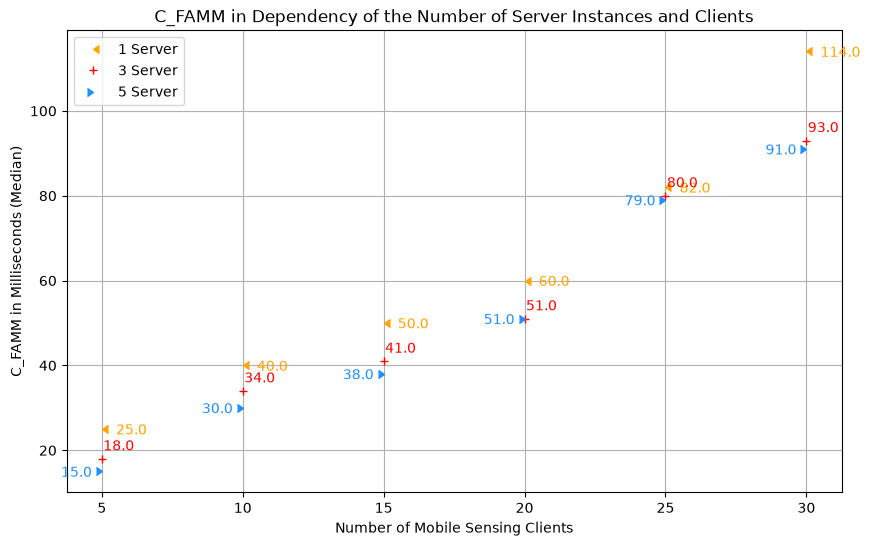

In [5]:
figure = plt.figure()

#plt.errorbar(dfCFAMM1Server['Number of Mobile Sensing Clients'], dfCFAMM1Server['C_FAMM (Median)'], dfCFAMM1Server['MAD'],linestyle='', marker='o', label='1 Server', color='orange')
#plt.errorbar(dfCFAMM3Server['Number of Mobile Sensing Clients'], dfCFAMM3Server['C_FAMM (Median)'], dfCFAMM3Server['MAD'],linestyle='', marker='o', label='3 Server', color='red')
#plt.errorbar(dfCFAMM5Server['Number of Mobile Sensing Clients'], dfCFAMM5Server['C_FAMM (Median)'], dfCFAMM5Server['MAD'],linestyle='', marker='o', label='5 Server', color='dodgerblue')

plt.plot(dfCFAMM1Server['Number of Mobile Sensing Clients'], dfCFAMM1Server['C_FAMM (Median)'],linestyle='', marker=4, label='1 Server', color='orange')
plt.plot(dfCFAMM3Server['Number of Mobile Sensing Clients'], dfCFAMM3Server['C_FAMM (Median)'],linestyle='', marker='+', label='3 Server', color='red')
plt.plot(dfCFAMM5Server['Number of Mobile Sensing Clients'], dfCFAMM5Server['C_FAMM (Median)'],linestyle='', marker=5, label='5 Server', color='dodgerblue')

plt.title("C_FAMM in Dependency of the Number of Server Instances and Clients")
plt.xlabel("Number of Mobile Sensing Clients")
plt.ylabel("C_FAMM in Milliseconds (Median)")

for i, row in dfCFAMM1Server.iterrows():
    #plt.text(x=row['Number of Mobile Sensing Clients']+0.5, y=row['C_FAMM (Median)']-1.25, s=round(row['MAD'], 2), color='orange', horizontalalignment='left')
    plt.text(x=row['Number of Mobile Sensing Clients']+0.5, y=row['C_FAMM (Median)']-1.25, s=row['C_FAMM (Median)'], color='orange', horizontalalignment='left')
for i, row in dfCFAMM3Server.iterrows():
    #plt.text(x=row['Number of Mobile Sensing Clients']+0.05, y=row['C_FAMM (Median)']+2, s=round(row['MAD'], 2), color='red')
    plt.text(x=row['Number of Mobile Sensing Clients']+0.05, y=row['C_FAMM (Median)']+2, s=row['C_FAMM (Median)'], color='red')
for i, row in dfCFAMM5Server.iterrows():
    #plt.text(x=row['Number of Mobile Sensing Clients']-0.35, y=row['C_FAMM (Median)']-1.25, s=round(row['MAD'], 2), color='dodgerblue', horizontalalignment='right')
    plt.text(x=row['Number of Mobile Sensing Clients']-0.35, y=row['C_FAMM (Median)']-1.25, s=row['C_FAMM (Median)'], color='dodgerblue', horizontalalignment='right')

plt.grid()
plt.legend()

figure.set_figwidth(10)
figure.set_figheight(6)

plt.show()

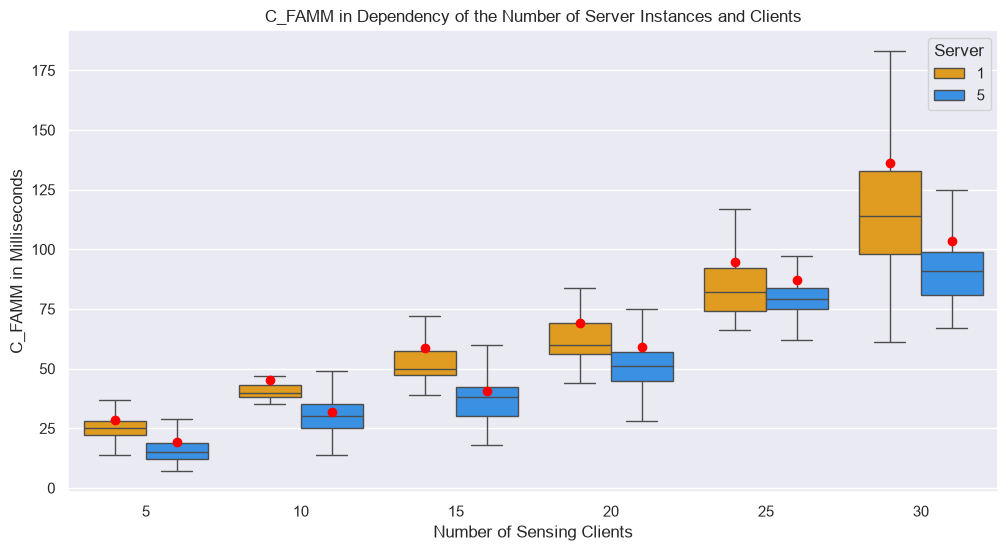

In [6]:
sns.set_theme(rc={"figure.figsize": (12,6)})

sns.boxplot(data=pd.concat([dfCFAMM1ServerBoxPlot, dfCFAMM5ServerBoxPlot]), showfliers=False, showmeans=True, meanprops={'marker': 'o', 'markerfacecolor': 'red', 'markeredgecolor':'red'}, hue="Server", x='Clients', y='C_FAMM', palette=['orange', 'dodgerblue']).set(title="C_FAMM in Dependency of the Number of Server Instances and Clients", xlabel="Number of Sensing Clients", ylabel="C_FAMM in Milliseconds")

#plt.grid()
plt.show()